# CVPR Assignment
**Name:** Tasmin Akther Tasu

**ID:** 23-54361-3

**Dataset  Link:** NOGAY, HIDIR SELCUK (2026), “Microscopic Image Dataset for CAT6 Cable Outer-Sheath Surface Condition Classification”, Mendeley Data, V1, doi: 10.17632/zs55dv63kv.1

## Step 1 - Importing Libraries

In [9]:
import os
import zipfile
from pathlib import Path
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
import seaborn as sns
print('Libraries imported successfully.')

Libraries imported successfully.


## Step 2 - Set Device

In [10]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)

Device: cpu


## Step 3 - Load  Dataset

In [11]:
KAGGLE_PATH = Path('/kaggle/input/datasets/tasminakter/tashu-cvpr-dataset')
work_root = Path('/kaggle/working')
class_folders = {'Bending_Damage', 'Intact', 'Severe_Damage'}

def find_data_folder(folder):
    for root, dirs, files in os.walk(folder):
        if class_folders.issubset(set(dirs)):
            return root
    return None

data_dir = find_data_folder(KAGGLE_PATH)
if data_dir is None:
    zip_files = sorted(KAGGLE_PATH.rglob('*.zip'))
    assert zip_files, 'Please attach the CAT6 dataset in Kaggle Add Input.'
    extract_to = work_root / 'CAT6_data'
    extract_to.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_files[0]) as z:
        z.extractall(extract_to)
    nested_zip = list(extract_to.rglob('Raw_Dataset.zip'))
    if nested_zip:
        with zipfile.ZipFile(nested_zip[0]) as z:
            z.extractall(extract_to)
    data_dir = find_data_folder(extract_to)

assert data_dir is not None, 'Cannot find the three CAT6 class folders.'
print('Dataset path:', data_dir)

Dataset path: /kaggle/input/datasets/tasminakter/tashu-cvpr-dataset/Raw_Dataset


## Step 4 - Image Transforms

In [12]:
train_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor()
])

val_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])
print('Train transforms:', train_transform)
print('Validation transforms:', val_transform)

Train transforms: Compose(
    Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=(0.8, 1.2), hue=None)
    ToTensor()
)
Validation transforms: Compose(
    Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
)


## Step 5 - Training and Test Datasets

In [13]:
all_data = datasets.ImageFolder(data_dir)
train_indices, test_indices = train_test_split(
    range(len(all_data)), test_size=0.2, random_state=42, stratify=all_data.targets
)
train_data = Subset(datasets.ImageFolder(data_dir, transform=train_transform), train_indices)
test_data = Subset(datasets.ImageFolder(data_dir, transform=val_transform), test_indices)
class_names = all_data.classes
print('Classes:', class_names)
print('Training images:', len(train_data))
print('Test/validation images:', len(test_data))

Classes: ['Bending_Damage', 'Intact', 'Severe_Damage']
Training images: 1920
Test/validation images: 480


## Step 6 - Display a Sample Image

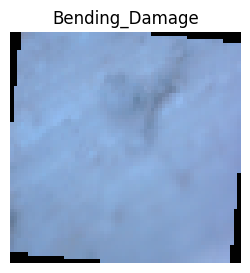

In [14]:
image, label = train_data[min(800, len(train_data) - 1)]
plt.figure(figsize=(3, 3))
plt.imshow(image.permute(1, 2, 0))
plt.title(class_names[label])
plt.axis('off')
plt.show()

## Step 7 - Set Hyperparameters


In [15]:
batch_size = 32                # 16 dile beshi batch, 64 dile kom batch; memory-o change hoy.
learning_rate = 0.001         # 0.0001 dile update chhoto, 0.01 dile boro (unstable hote pare).
minimum_learning_rate = 1e-4  # 1e-5 dile shesher LR aro kom, 5e-4 dile beshi thakbe.
epochs = 20                   # 10 dile kom training, 30 dile beshi (overfitting hote pare).
print(f'Epochs: {epochs} | Batch Size: {batch_size} | Learning Rate: {learning_rate} | Minimum Learning Rate: {minimum_learning_rate}')

Epochs: 20 | Batch Size: 32 | Learning Rate: 0.001 | Minimum Learning Rate: 0.0001


## Step 8 - Create DataLoaders

In [16]:
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True,
                          num_workers=2)
val_loader = DataLoader(test_data, batch_size=batch_size, shuffle=True,
                        num_workers=2)
print('Training batches:', len(train_loader))
print('Test/validation batches:', len(val_loader))

Training batches: 60
Test/validation batches: 15


## Step 9 - Build CNN Model

In [17]:
class CNNModel(nn.Module):
    def __init__(self, num_classes=3):
        super(CNNModel, self).__init__()
       
        self.conv_layers = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3),    # 3x64x64 -> 64x62x62
            nn.MaxPool2d(2),                   # 64x31x31
            nn.ReLU(),

            nn.Conv2d(64, 128, kernel_size=3), # 128x29x29
            nn.MaxPool2d(2),                   # 128x14x14
            nn.ReLU(),

            nn.Conv2d(128, 128, kernel_size=3),# 128x12x12
            nn.MaxPool2d(2),                   # 128x6x6
            nn.ReLU()
        )
     
        self.fc_layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 6 * 6, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x
print('CNNModel defined: 3 convolution layers, 3 output classes.')

CNNModel defined: 3 convolution layers, 3 output classes.


## Step 10 - Adam and CrossEntropyLoss

In [18]:
from torch.optim import Adam
from torch.optim.lr_scheduler import CosineAnnealingLR

model = CNNModel(num_classes=3).to(device)
optimizer = Adam(model.parameters(), lr=learning_rate)
scheduler = CosineAnnealingLR(optimizer, T_max=epochs, eta_min=minimum_learning_rate)
criterion = nn.CrossEntropyLoss()
print('Optimizer:', optimizer.__class__.__name__)
print('Loss:', criterion)
print('Scheduler:', scheduler.__class__.__name__)

Optimizer: Adam
Loss: CrossEntropyLoss()
Scheduler: CosineAnnealingLR


## Step 11 - Model Summary

In [19]:
try:
    from torchsummary import summary
    summary(model, input_size=(3, 64, 64), device=device)
except ImportError:
    print(model)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 62, 62]           1,792
         MaxPool2d-2           [-1, 64, 31, 31]               0
              ReLU-3           [-1, 64, 31, 31]               0
            Conv2d-4          [-1, 128, 29, 29]          73,856
         MaxPool2d-5          [-1, 128, 14, 14]               0
              ReLU-6          [-1, 128, 14, 14]               0
            Conv2d-7          [-1, 128, 12, 12]         147,584
         MaxPool2d-8            [-1, 128, 6, 6]               0
              ReLU-9            [-1, 128, 6, 6]               0
          Flatten-10                 [-1, 4608]               0
           Linear-11                  [-1, 256]       1,179,904
             ReLU-12                  [-1, 256]               0
          Dropout-13                  [-1, 256]               0
           Linear-14                   

## Step 12 - Training Function

In [20]:
def train_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0
    correct = 0
    total = 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        total_loss += loss.item()
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    train_loss = total_loss / len(loader)
    train_acc = correct / total
    return train_loss, train_acc
print('Training function ready:', train_epoch.__name__)

Training function ready: train_epoch


## Step 13 - Validation Function

In [21]:
def validate_epoch(model, loader, criterion, device):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
    val_loss = total_loss / len(loader)
    val_acc = correct / total
    return val_loss, val_acc
print('Validation function ready:', validate_epoch.__name__)

Validation function ready: validate_epoch


## Step 14 - Train CNN

In [22]:
train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

for epoch in range(epochs):
    print('--')
    print(f"Epoch {epoch+1}/{epochs}, LR: {optimizer.param_groups[0]['lr']:.6g}")
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion, device)
    val_loss, val_acc = validate_epoch(model, val_loader, criterion, device)
    scheduler.step()

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    print(f'Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}')
    print(f'Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}')

--
Epoch 1/20, LR: 0.001
Train Loss: 0.9480 | Train Acc: 0.5089
Val Loss: 0.7656 | Val Acc: 0.6875
--
Epoch 2/20, LR: 0.00099446
Train Loss: 0.7026 | Train Acc: 0.6708
Val Loss: 0.6937 | Val Acc: 0.7104
--
Epoch 3/20, LR: 0.000977975
Train Loss: 0.6590 | Train Acc: 0.6958
Val Loss: 0.5190 | Val Acc: 0.8167
--
Epoch 4/20, LR: 0.000950953
Train Loss: 0.5922 | Train Acc: 0.7469
Val Loss: 0.5130 | Val Acc: 0.7479
--
Epoch 5/20, LR: 0.000914058
Train Loss: 0.5562 | Train Acc: 0.7635
Val Loss: 0.5937 | Val Acc: 0.7000
--
Epoch 6/20, LR: 0.000868198
Train Loss: 0.5719 | Train Acc: 0.7547
Val Loss: 0.5212 | Val Acc: 0.7458
--
Epoch 7/20, LR: 0.000814503
Train Loss: 0.4974 | Train Acc: 0.7927
Val Loss: 0.6516 | Val Acc: 0.7250
--
Epoch 8/20, LR: 0.000754296
Train Loss: 0.5080 | Train Acc: 0.7885
Val Loss: 0.5104 | Val Acc: 0.8438
--
Epoch 9/20, LR: 0.000689058
Train Loss: 0.4915 | Train Acc: 0.7937
Val Loss: 0.5992 | Val Acc: 0.6771
--
Epoch 10/20, LR: 0.000620396
Train Loss: 0.4509 | Train Acc

## Step 15 - Accuracy and Loss Graph showing

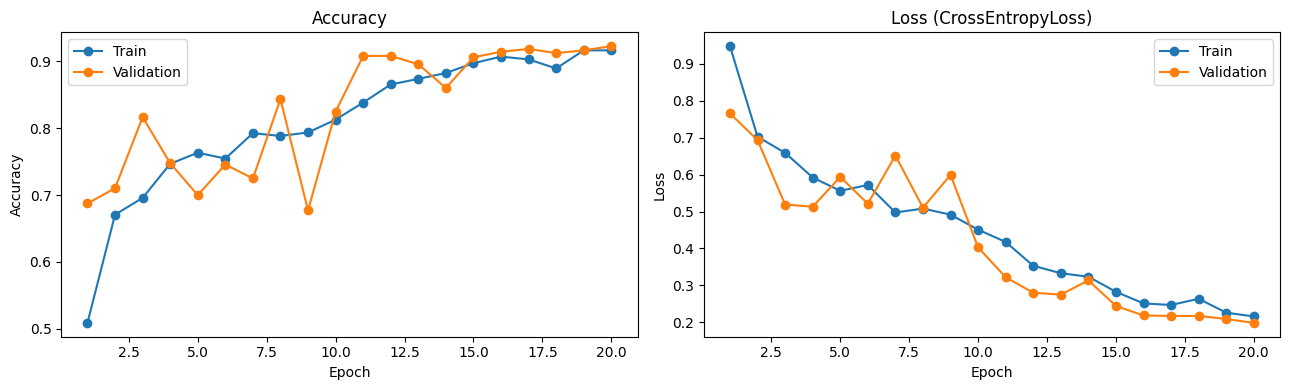

In [23]:
epochs_number = np.arange(1, epochs + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(epochs_number, train_accuracies, marker='o', label='Train')
axes[0].plot(epochs_number, val_accuracies, marker='o', label='Validation')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Accuracy')
axes[0].legend()

axes[1].plot(epochs_number, train_losses, marker='o', label='Train')
axes[1].plot(epochs_number, val_losses, marker='o', label='Validation')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].set_title('Loss (CrossEntropyLoss)')
axes[1].legend()
plt.tight_layout()
plt.show()

## Step 16 - Single Image Prediction

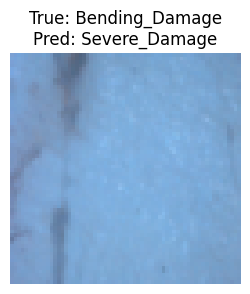

In [24]:
ix = torch.randint(0, len(test_data), ()).item()
img, true_label = test_data[ix]
img_input = img.unsqueeze(0).to(device)
model.eval()
with torch.no_grad():
    np_output = model(img_input).cpu().numpy()
pred = np.exp(np_output - np_output.max())
pred = pred / np.sum(pred)
plt.figure(figsize=(3, 3))
plt.imshow(img.permute(1, 2, 0))
plt.title(f'True: {class_names[true_label]}\nPred: {class_names[pred[0].argmax()]}')
plt.axis('off')
plt.show()

## Step 17 - Find Misclassified Image

In [25]:
model.eval()
misclassified = []
all_preds = []
all_labels = []
with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        for img, true, pred_label in zip(images, labels, preds):
            if true.item() != pred_label.item():
                misclassified.append((img.cpu(), true.item(), pred_label.item()))
print('Total misclassified samples:', len(misclassified))

Total misclassified samples: 37


## Step 18 - Display Misclassified Image

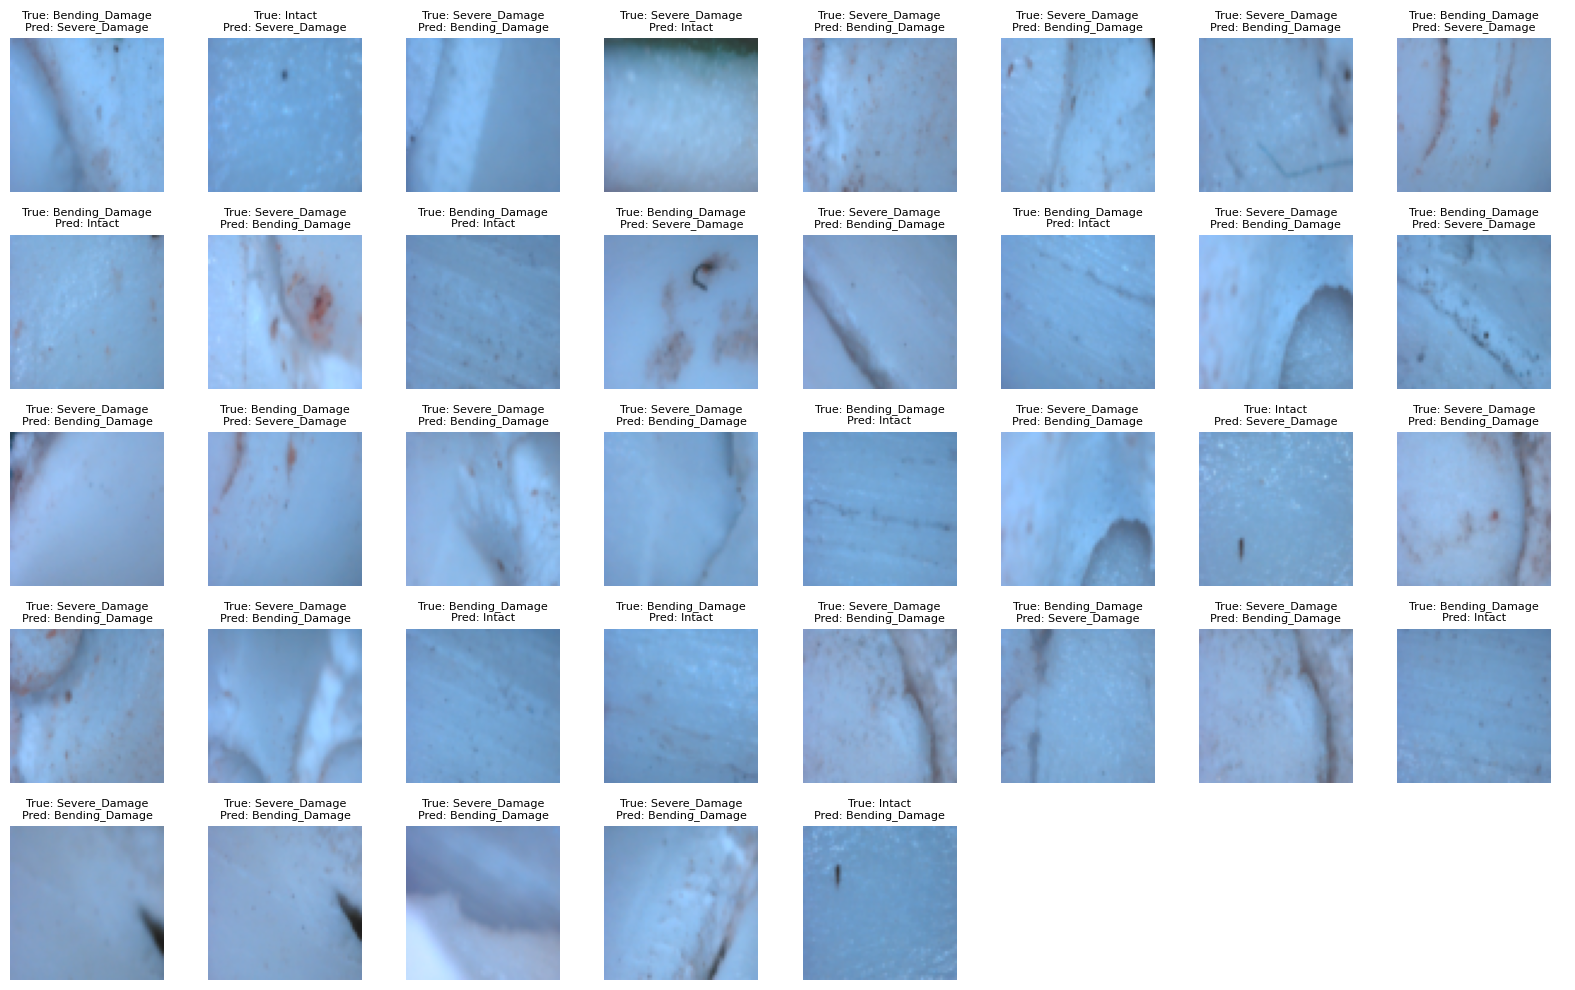

In [26]:
num_rows = 5
num_cols = 8
num_to_show = min(num_rows * num_cols, len(misclassified))
fig, axes = plt.subplots(num_rows, num_cols, figsize=(16, 10))
axes = axes.flatten()
for idx in range(num_to_show):
    img, true, pred_label = misclassified[idx]
    axes[idx].imshow(img.permute(1, 2, 0).numpy())
    axes[idx].set_title(f'True: {class_names[true]}\nPred: {class_names[pred_label]}', fontsize=8)
    axes[idx].axis('off')
for idx in range(num_to_show, len(axes)):
    axes[idx].axis('off')
plt.tight_layout()
plt.show()

## Step 19 - Confusion Matrix

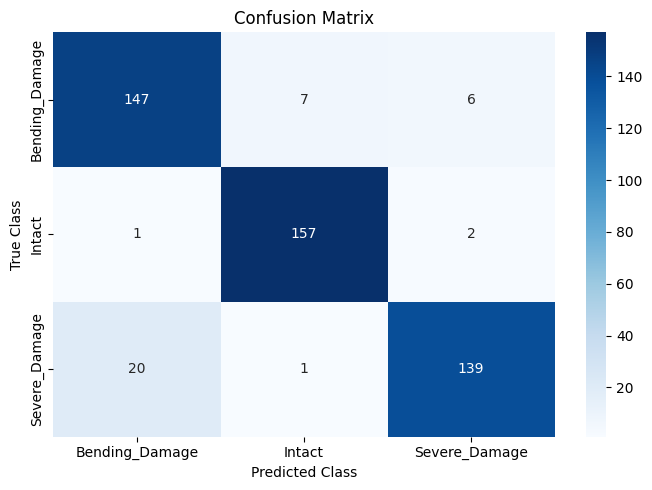

In [27]:
cm = confusion_matrix(all_labels, all_preds, labels=[0, 1, 2])
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Class')
plt.ylabel('True Class')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

## Step 20 - Feature Maps

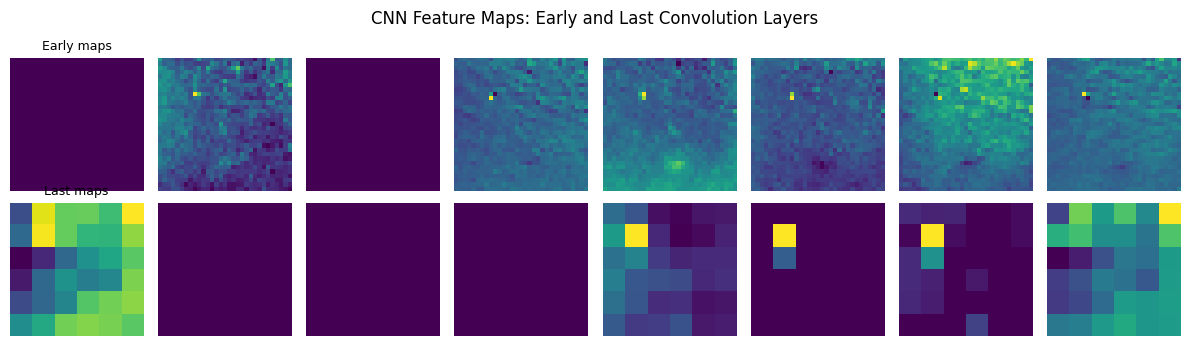

In [28]:
img, _ = test_data[0]
x = img.unsqueeze(0).to(device)
model.eval()
with torch.no_grad():
    first_maps = model.conv_layers[:3](x).cpu()[0]  
    last_maps = model.conv_layers(x).cpu()[0]      

fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for i in range(8):
    axes[0, i].imshow(first_maps[i], cmap='viridis')
    axes[0, i].axis('off')
    axes[1, i].imshow(last_maps[i], cmap='viridis')
    axes[1, i].axis('off')
axes[0, 0].set_title('Early maps', fontsize=9)
axes[1, 0].set_title('Last maps', fontsize=9)
plt.suptitle('CNN Feature Maps: Early and Last Convolution Layers')
plt.tight_layout()
plt.show()